# Rare-event Monte Carlo
**Notebook author: Ziad Mosalam**

Companion to *Bayesian Methods for Autonomous Robotics and Intelligent Infrastructure Systems* by Khalid M. Mosalam.

The elementary Monte Carlo notebook estimates ordinary averages and the area of a circle. Here we study an event that ordinary sampling rarely sees. A deliberately simple Gaussian limit state gives us an exact answer against which to check both ordinary Monte Carlo and importance sampling. The model is synthetic and dimensionless; it is not a failure probability for a particular structure.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ndtr

plt.style.use('book.mplstyle')
figure_dir = Path('../figures')
figure_dir.mkdir(exist_ok=True)
BLUE, GOLD, TEAL = '#003262', '#B17A00', '#247C86'
INK = '#30363B'


## A rare limit-state exceedance
Let $X_1,X_2$ be independent standard Gaussian variables. Define the standardized demand
$$S=(X_1+X_2)/\sqrt{2},\qquad F=\{S>\beta\},\qquad\beta=3.5.$$
Then $S\sim N(0,1)$ and $P(F)=\Phi(-\beta)$. This analytic value is a verification target, not an input to either estimator.

Plain Monte Carlo samples from $p(s)=N(0,1)$. Importance sampling draws from $q(s)=N(\beta,1)$, placing samples near the failure boundary. Every failure is weighted by the likelihood ratio
$$w(s)=\frac{p(s)}{q(s)}=\exp(-\beta s+\beta^2/2),\qquad \widehat P_{\mathrm{IS}}=\frac1N\sum_i\mathbf1\{S_i>\beta\}w(S_i).$$
The weights are **not** divided by their sample sum. This is an ordinary unbiased importance-sampling estimate, not a self-normalized estimate.

In [2]:
beta = 3.5
exact_probability = float(ndtr(-beta))
proposal_mean = beta
sample_sizes = np.unique(np.geomspace(100, 100_000, 36).astype(int))
replications = 64

# A two-dimensional view of the same limit state.
# The proposal shifts along (1,1), while the orthogonal coordinate is unchanged.
geometry_rng = np.random.default_rng(17)
plain_points = geometry_rng.normal(size=(700, 2))
shift = np.full(2, beta / np.sqrt(2))
proposal_points = geometry_rng.normal(size=(700, 2)) + shift

print(f'Exact exceedance probability: {exact_probability:.8f}')
print(f'Expected plain-Monte-Carlo failures in 1,000 samples: {1000*exact_probability:.3f}')


Exact exceedance probability: 0.00023263
Expected plain-Monte-Carlo failures in 1,000 samples: 0.233


## Independent repeated experiments
We repeat the experiment 64 times. Within each repetition, cumulative sums give estimates at increasing sample counts. The two methods use separate random streams. We simulate the scalar coordinate S directly because the orthogonal coordinate cancels from the likelihood ratio and does not affect the event.

The shaded ranges below contain the middle 80% of the repeated estimates. They describe repeat-to-repeat variability in this experiment; they are not confidence intervals for one run.

At small sample counts, a zero estimate usually means no exceedance was observed. It does not establish that the event is impossible. The ordinary estimator's quantile envelope need not shrink monotonically because rare hits enter discrete counts.

In [3]:
plain_estimates = np.empty((replications, len(sample_sizes)))
importance_estimates = np.empty_like(plain_estimates)

for run in range(replications):
    plain_rng = np.random.default_rng(np.random.SeedSequence([2026, run, 0]))
    importance_rng = np.random.default_rng(np.random.SeedSequence([2026, run, 1]))
    plain_s = plain_rng.normal(size=sample_sizes[-1])
    proposal_s = importance_rng.normal(proposal_mean, 1.0, size=sample_sizes[-1])
    contributions = (proposal_s > beta) * np.exp(
        -proposal_mean*proposal_s + 0.5*proposal_mean**2)
    plain_estimates[run] = np.cumsum(plain_s > beta)[sample_sizes-1] / sample_sizes
    importance_estimates[run] = np.cumsum(contributions)[sample_sizes-1] / sample_sizes

# Exact one-sample variances make the Monte Carlo error comparison checkable.
plain_variance = exact_probability * (1.0-exact_probability)
importance_second_moment = np.exp(proposal_mean**2) * ndtr(-beta-proposal_mean)
importance_variance = importance_second_moment - exact_probability**2
plain_relative_rmse = np.sqrt(plain_variance / sample_sizes) / exact_probability
importance_relative_rmse = np.sqrt(importance_variance / sample_sizes) / exact_probability


## Why the proposal helps
Under the shifted proposal, many points fall on each side of the boundary. Their contributions are weighted back to the target distribution, so oversampling the rare region does not change the quantity being estimated. Both error curves retain the $N^{-1/2}$ rate. Importance sampling changes the variance constant, not the rate.

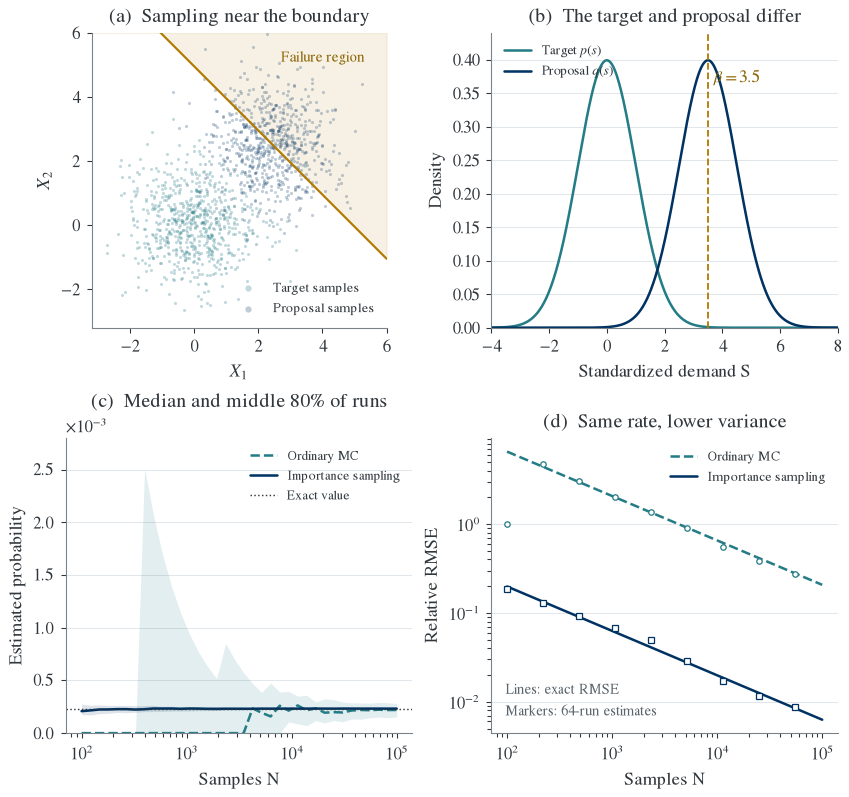

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(6.5, 6.1), layout='constrained')
ax = axes[0, 0]
boundary_x = np.linspace(-3.2, 6.0, 200)
boundary_y = beta*np.sqrt(2) - boundary_x
ax.fill_between(boundary_x, boundary_y, 6, color=GOLD, alpha=.10)
ax.scatter(plain_points[:, 0], plain_points[:, 1], s=3, color=TEAL, alpha=.28,
           linewidths=0, label='Target samples')
ax.scatter(proposal_points[:, 0], proposal_points[:, 1], s=3, color=BLUE, alpha=.25,
           linewidths=0, label='Proposal samples')
ax.plot(boundary_x, boundary_y, color=GOLD, linewidth=1.2)
ax.set(xlim=(-3.2, 6), ylim=(-3.2, 6), xlabel=r'$X_1$', ylabel=r'$X_2$',
       title='(a)  Sampling near the boundary', aspect='equal')
ax.text(4.0, 5.1, 'Failure region', fontsize=8, ha='center', color='#8A6200')
ax.legend(loc='lower right', fontsize=7.5, markerscale=2)

ax = axes[0, 1]
s = np.linspace(-4, 8, 500)
pdf = lambda x: np.exp(-.5*x*x)/np.sqrt(2*np.pi)
ax.plot(s, pdf(s), color=TEAL, label=r'Target $p(s)$')
ax.plot(s, pdf(s-beta), color=BLUE, label=r'Proposal $q(s)$')
ax.fill_between(s, 0, pdf(s), where=s>beta, color=GOLD, alpha=.5)
ax.axvline(beta, color=GOLD, linewidth=1, linestyle='--')
ax.text(beta+.2, .365, r'$\beta=3.5$', fontsize=9, color='#8A6200')
ax.set(xlim=(-4, 8), ylim=(0, .44), xlabel='Standardized demand S', ylabel='Density',
       title='(b)  The target and proposal differ')
ax.legend(loc='upper left', fontsize=7.5)
ax.grid(axis='y')

ax = axes[1, 0]
for values, color, label, ls in [(plain_estimates, TEAL, 'Ordinary MC', '--'),
                                 (importance_estimates, BLUE, 'Importance sampling', '-')]:
    low, median, high = np.quantile(values, [.1, .5, .9], axis=0)
    ax.fill_between(sample_sizes, low, high, color=color, alpha=.13, linewidth=0)
    ax.plot(sample_sizes, median, color=color, linestyle=ls, label=label)
ax.axhline(exact_probability, color=INK, linewidth=.8, linestyle=':', label='Exact value')
ax.set(xscale='log', ylim=(0, .0028), xlabel='Samples N', ylabel='Estimated probability',
       title='(c)  Median and middle 80% of runs')
ax.ticklabel_format(axis='y', style='sci', scilimits=(-3, 3), useMathText=True)
ax.legend(loc='upper right', fontsize=7.3)
ax.grid(axis='y')

ax = axes[1, 1]
for values, theory, color, label, ls, marker in [
    (plain_estimates, plain_relative_rmse, TEAL, 'Ordinary MC', '--', 'o'),
    (importance_estimates, importance_relative_rmse, BLUE, 'Importance sampling', '-', 's')]:
    empirical = np.sqrt(np.mean((values-exact_probability)**2, axis=0))/exact_probability
    ax.loglog(sample_sizes, theory, color=color, linestyle=ls, label=label)
    ax.loglog(sample_sizes[::4], empirical[::4], linestyle='none', marker=marker,
              markersize=3, markerfacecolor='white', markeredgewidth=.7, color=color)
ax.text(.04, .06, 'Lines: exact RMSE\nMarkers: 64-run estimates', transform=ax.transAxes,
        fontsize=7.8, color='#58636B')
ax.set(xlabel='Samples N', ylabel='Relative RMSE', title='(d)  Same rate, lower variance')
ax.legend(loc='upper right', fontsize=7.5)
ax.grid(which='major', axis='y')
fig.savefig(figure_dir / 'rare-event-monte-carlo.pdf')
fig.savefig(figure_dir / 'rare-event-monte-carlo.png')
plt.show()


## Verification
For a general shift $\mu$, the weighted indicator has second moment
$$E_q[(\mathbf1_F w)^2]=e^{\mu^2}\Phi(-\beta-\mu).$$
We check this expression using independent quadrature, and compare the replicated estimates with the exact probability using their known sampling standard error. A five-standard-error check is a diagnostic for this fixed seeded experiment, not a universal pass criterion for statistical methods.

In [5]:
from scipy.integrate import quad

def weighted_integrand(s):
    q = np.exp(-.5*(s-proposal_mean)**2)/np.sqrt(2*np.pi)
    w = np.exp(-proposal_mean*s + .5*proposal_mean**2)
    return q*w

integrated_probability = quad(weighted_integrand, beta, np.inf,
                              epsabs=1e-12, epsrel=1e-10)[0]
assert np.isclose(integrated_probability, exact_probability, rtol=1e-9)

def squared_contribution_integrand(s):
    # Combine exponents before exponentiation to avoid a 0 * infinity product.
    exponent = -0.5*(s-proposal_mean)**2 - 2*proposal_mean*s + proposal_mean**2
    return np.exp(exponent)/np.sqrt(2*np.pi)

integrated_second_moment = quad(squared_contribution_integrand, beta, np.inf,
                               epsabs=1e-14, epsrel=1e-10)[0]
assert np.isclose(integrated_second_moment, importance_second_moment, rtol=1e-9)
assert 0 < importance_variance < plain_variance
for values, variance in [(plain_estimates, plain_variance),
                         (importance_estimates, importance_variance)]:
    aggregate_se = np.sqrt(variance / (sample_sizes[-1]*replications))
    assert abs(values[:, -1].mean()-exact_probability) < 5*aggregate_se

print(f'Theoretical variance reduction: {plain_variance/importance_variance:.1f} times')
print('Exact integral and repeated-estimator checks passed.')


Theoretical variance reduction: 1090.2 times
Exact integral and repeated-estimator checks passed.


The shifted Gaussian is effective because this example has one known linear failure boundary. A proposal that misses important failure regions can perform poorly for curved or disconnected boundaries. The original Monte Carlo notebook and its elementary calculations are retained unchanged.